# Centralized model evaluation

Sweeps every model (SRCNN, DSCMS, PRUSR, SoFoNO, SRNO) across every trained loss
strategy (mse, mse_lpips, mse_lpips_ke) found under `../models/`, and for each:

1. Computes average metrics (MSE, SSIM, PSNR, LPIPS, FSIM, EPI, TKE) over the
   full test set (2022-2024).
2. Plots the kinetic-energy spectrum (LR / Prediction / HR) for one fixed
   sample, with a zoomed inset on the mid/high-wavenumber band.

Replaces `evaluate_model.ipynb` and `02_notebook.ipynb` — both are single-model
or metrics-only; this combines both into one sweep, reusing the same
`model_factory` training uses so new models need no extra wiring here.

In [1]:
import os
import glob
from collections import OrderedDict

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
from torch.utils.data import DataLoader
import sys

sys.path.append('..')

from models.model_factory import create_model
from datasets.super_res_dataset import SuperResDataset
from evaluation.evaluate import evaluate_model
from metrics.kinetic_energy_spectrum import compute_energy_spectrum
from metrics.image_metrics import (
    mseLoss, ssimLoss, psnrLoss, lpipsLoss, fsimLoss, epiLoss,
)
from metrics.physical_metrics import LossTKE
from metrics.kinetic_energy_spectrum import (
    KineticEnergySpectrumLoss, WeightedKineticEnergySpectrumLoss,
)


Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [off]


/home/lcadame/Vinicius_Thesis/Vinicius/venv/lib/python3.11/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/lcadame/Vinicius_Thesis/Vinicius/venv/lib/python3.11/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: /home/lcadame/Vinicius_Thesis/Vinicius/venv/lib/python3.11/site-packages/lpips/weights/v0.1/vgg.pth


In [2]:
# --- Configuration ---

# Canonical test split (matches split_dataset.py / train.py's held-out years)
TEST_FILES = [
    "../hycom_numpy/hycom_2022.npy",
    "../hycom_numpy/hycom_2023.npy",
    "../hycom_numpy/hycom_2024.npy",
]

# Must match the LR-degradation hyperparameters used in train.py's main()
DOWNSAMPLE_FACTOR = 1
FREQ_THRESHOLD = 10

# Directory names under models/ (note: SoFoNO's checkpoint filenames are
# still upper()'d to SOFONO_best.pth by train.py, handled below)
MODELS_TO_TEST = ["SRCNN"]
MODELS_TO_TEST = ["SRCNN", "DSCMS", "PRUSR", "SoFoNO", "SRNO"]
BASE_MODEL_DIR = os.path.abspath("../models")

SAMPLE_IDX = 0  # fixed test-set sample used for the qualitative spectrum plots
PLOTS_DIR = "eval_plots"
os.makedirs(PLOTS_DIR, exist_ok=True)

RESULTS_CSV = "evaluation_results_summary.csv"

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# Shared KE / weighted-KE loss modules (must be .to(device) explicitly --
# they're nn.Module buffers, not moved automatically like plain tensors)
ke_loss_fn = KineticEnergySpectrumLoss(size=128).to(device)
wke_loss_fn = WeightedKineticEnergySpectrumLoss(size=128).to(device)


Using device: cuda


In [3]:
test_dataset = SuperResDataset(
    hr_files=TEST_FILES,
    downsample_factor=DOWNSAMPLE_FACTOR,
    freq_threshold=FREQ_THRESHOLD,
)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False)
print(f"Test set size: {len(test_dataset)}")


Loading datasets...
../hycom_numpy/hycom_2022.npy: (365, 128, 128, 2)
../hycom_numpy/hycom_2023.npy: (365, 128, 128, 2)
../hycom_numpy/hycom_2024.npy: (244, 128, 128, 2)
Loaded 974 samples.
Dataset shape: (974, 128, 128, 2)
Test set size: 974


## Helpers: checkpoint discovery, model loading, spectrum plot

In [4]:
def find_checkpoints(model_name, base_dir=BASE_MODEL_DIR):
    """Finds every best checkpoint under models/{model_name}/, regardless of
    how many run/timestamp folders are nested beneath the experiment folder
    (train.py appends a timestamp subfolder as of the latest refactor).

    Labels each checkpoint by its top-level experiment folder name, e.g.
    "test_composite_loss_mse_lpips_0.6_0.4".
    """
    model_dir = os.path.join(base_dir, model_name)
    filename = f"{model_name.upper()}_best.pth"
    pattern = os.path.join(model_dir, "**", "output", "weights", filename)

    checkpoints = []
    for weight_path in sorted(glob.glob(pattern, recursive=True)):
        relative = os.path.relpath(weight_path, model_dir)
        experiment_name = relative.split(os.sep)[0]
        checkpoints.append((experiment_name, weight_path))
    return checkpoints


def categorize_strategy(experiment_name):
    """Buckets an experiment folder name into one of the three loss strategies."""
    name = experiment_name.lower()
    if "ke" in name:
        return "mse_lpips_ke"
    if "lpips" in name:
        return "mse_lpips"
    if "mse" in name:
        return "mse"
    return "unknown"


In [5]:
def load_model(model_name, weight_path):
    """Instantiates the model via the same factory train.py uses, loads the
    checkpoint (stripping a DataParallel "module." prefix if present), and
    wraps it back in DataParallel for eval (matches how it may have trained)."""
    model = create_model(model_name.lower(), in_channels=2, out_channels=2)

    checkpoint = torch.load(weight_path, map_location=device)
    state_dict = checkpoint.get("model_state_dict", checkpoint)

    cleaned = OrderedDict(
        (k[len("module."):] if k.startswith("module.") else k, v)
        for k, v in state_dict.items()
    )
    model.load_state_dict(cleaned)

    model = model.to(device)
    model = torch.nn.DataParallel(model)
    model.eval()
    return model


In [6]:
def plot_ke_spectrum(title, lr_np, pred_np, hr_np, save_path):
    """Two-panel KE spectrum plot: full spectrum (LR/Pred/HR) with a zoomed
    inset over the mid/high-wavenumber band, plus Prediction-vs-HR alone."""
    k_lr, E_lr = compute_energy_spectrum(lr_np)
    k_pred, E_pred = compute_energy_spectrum(pred_np)
    k_hr, E_hr = compute_energy_spectrum(hr_np)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5), dpi=100, constrained_layout=True)
    fig.suptitle(title, fontsize=13, fontweight="bold")

    # --- Left panel: full spectrum + inset ---
    ax1.loglog(k_lr, E_lr, label="LR", lw=2, color="tab:blue")
    ax1.loglog(k_pred, E_pred, label="Prediction", lw=2, color="tab:orange")
    ax1.loglog(k_hr, E_hr, label="HR", lw=2, color="tab:red")
    ax1.set_title("Complete Spectrum")
    ax1.set_xlabel("Spatial Wavenumber (k)")
    ax1.set_ylabel("Kinetic Energy $E(k)$")
    ax1.grid(True, which="both", ls="--", alpha=0.4)
    ax1.legend()

    # Zoom into the mid/high-wavenumber band, where model vs. HR tend to
    # diverge, with limits derived from the actual data (not hardcoded) so
    # this holds up across models/strategies with very different magnitudes.
    k_max = k_hr.max()
    zoom_lo, zoom_hi = k_max * 0.15, k_max * 0.65
    zoom_mask = (k_hr >= zoom_lo) & (k_hr <= zoom_hi)
    zoom_vals = np.concatenate([E_pred[zoom_mask], E_hr[zoom_mask]])
    zoom_vals = zoom_vals[zoom_vals > 0]

    if zoom_mask.sum() >= 2 and zoom_vals.size > 0:
        axins = inset_axes(ax1, width="42%", height="42%", loc="lower left", borderpad=7)
        axins.loglog(k_pred, E_pred, color="tab:orange", lw=2)
        axins.loglog(k_hr, E_hr, color="tab:red", lw=2)
        axins.set_xlim(zoom_lo, zoom_hi)
        axins.set_ylim(zoom_vals.min() * 0.5, zoom_vals.max() * 2)
        axins.grid(True, which="both", ls="--", alpha=0.3)
        mark_inset(ax1, axins, loc1=2, loc2=4, fc="none", ec="0.5", lw=1)

    # --- Right panel: Prediction vs HR only ---
    ax2.loglog(k_pred, E_pred, label="Prediction", lw=2.5, color="tab:orange")
    ax2.loglog(k_hr, E_hr, label="HR", lw=2.5, color="tab:red")
    ax2.set_title("Prediction vs HR")
    ax2.set_xlabel("Spatial Wavenumber (k)")
    ax2.set_ylabel("Kinetic Energy $E(k)$")
    ax2.grid(True, which="both", ls="--", alpha=0.4)
    ax2.legend()

    plt.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()


In [7]:
def _panel_metrics_text(pred, target, channel, ke_val=None, wke_val=None):
    """pred/target: (1, 2, H, W) tensors. Metrics computed against target,
    same functions/order evaluate_model() uses so numbers here are directly
    comparable to the summary table. ke_val/wke_val (if given) are the
    channel-combined KE / Weighted-KE losses, appended as extra lines."""
    mse_v = mseLoss(pred, target, channel, 0)
    ssim_v = ssimLoss(pred, target, channel, 0)
    psnr_v = psnrLoss(pred, target, channel, 0)
    lpips_v = lpipsLoss(pred, target, channel, 0)
    fsim_v = fsimLoss(pred, target, channel, 0)
    epi_v = epiLoss(pred, target, channel, 0)
    tke_v = LossTKE(pred, target, channel, 0)
    text = (
        f"MSE: {mse_v:.6f}  SSIM: {ssim_v:.4f}  PSNR: {psnr_v:.2f} dB\n"
        f"LPIPS: {lpips_v:.4f}  FSIM: {fsim_v:.4f}  EPI: {epi_v:.4f}\n"
        f"TKE: {tke_v:.6f}"
    )
    if ke_val is not None:
        text += f"  KE: {ke_val:.4e}"
    if wke_val is not None:
        text += f"  WKE: {wke_val:.4e}"
    return text


def plot_sample_comparison(title, lr_t, pred_t, hr_t, save_path):
    """LR / Prediction / HR panels for both channels (u, v), with per-panel
    metrics (LR vs HR, Prediction vs HR) for the same fixed SAMPLE_IDX used
    by plot_ke_spectrum, so every model/strategy is judged on one sample.

    KE and Weighted-KE are channel-combined (they mix u and v internally),
    so the same value is shown under both the u-row and v-row panels.

    Metrics text lives in its own dedicated gridspec row below each image
    row, rather than a manual ax.text() offset below the image axes --
    imshow's forced 1:1 aspect ratio makes the image axes' actual on-figure
    size unpredictable, so a transAxes-fraction offset doesn't reliably land
    in the same place twice. A dedicated cell is a hard layout guarantee.
    """
    lr_np = lr_t.squeeze(0).cpu().numpy()
    pred_np = pred_t.squeeze(0).detach().cpu().numpy()
    hr_np = hr_t.squeeze(0).cpu().numpy()

    with torch.no_grad():
        ke_lr, wke_lr = ke_loss_fn(lr_t, hr_t).item(), wke_loss_fn(lr_t, hr_t).item()
        ke_pred, wke_pred = ke_loss_fn(pred_t, hr_t).item(), wke_loss_fn(pred_t, hr_t).item()

    channel_names = ["u-velocity", "v-velocity"]

    fig = plt.figure(figsize=(15, 11))
    gs = fig.add_gridspec(4, 3, height_ratios=[3, 1, 3, 1], hspace=0.35, wspace=0.15)
    fig.suptitle(title, fontsize=13, fontweight="bold", y=0.995)

    for ch, ch_name in enumerate(channel_names):
        img_row, text_row = 2 * ch, 2 * ch + 1
        vmin = min(lr_np[ch].min(), pred_np[ch].min(), hr_np[ch].min())
        vmax = max(lr_np[ch].max(), pred_np[ch].max(), hr_np[ch].max())

        panels = [
            ("LR", lr_np[ch], _panel_metrics_text(lr_t, hr_t, ch, ke_lr, wke_lr)),
            ("Prediction", pred_np[ch], _panel_metrics_text(pred_t, hr_t, ch, ke_pred, wke_pred)),
            ("Ground Truth HR", hr_np[ch], None),
        ]

        for col, (name, img, text) in enumerate(panels):
            ax_img = fig.add_subplot(gs[img_row, col])
            ax_img.imshow(img, cmap="viridis", vmin=vmin, vmax=vmax)
            ax_img.set_title(f"{name} ({ch_name})")
            ax_img.axis("off")

            ax_text = fig.add_subplot(gs[text_row, col])
            ax_text.axis("off")
            if text is not None:
                ax_text.text(0.5, 0.95, text, ha="center", va="top", fontsize=8,
                              transform=ax_text.transAxes)

    plt.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()


## Sweep every model \u00d7 strategy


--- Evaluating SRCNN_test_composite_loss_mse_05_08_2026 (mse) ---
Weights: /home/lcadame/Vinicius_Thesis/Vinicius/models/SRCNN/test_composite_loss_mse_05_08_2026/output/weights/SRCNN_best.pth


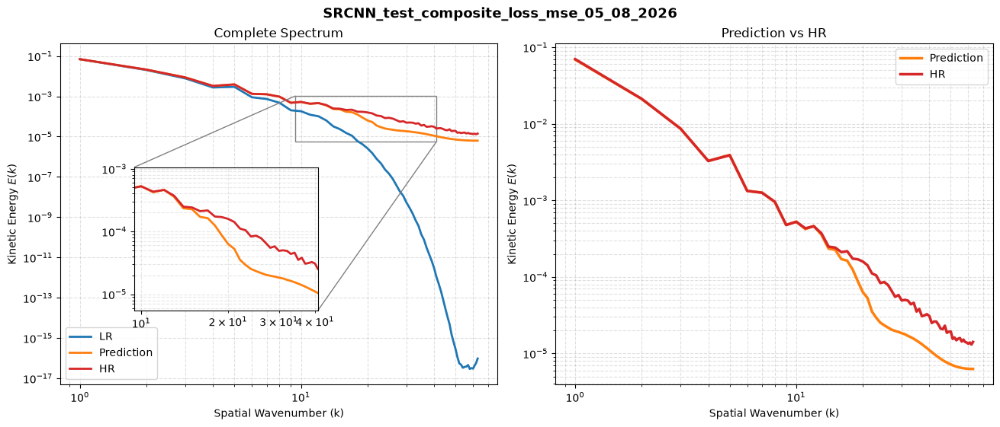

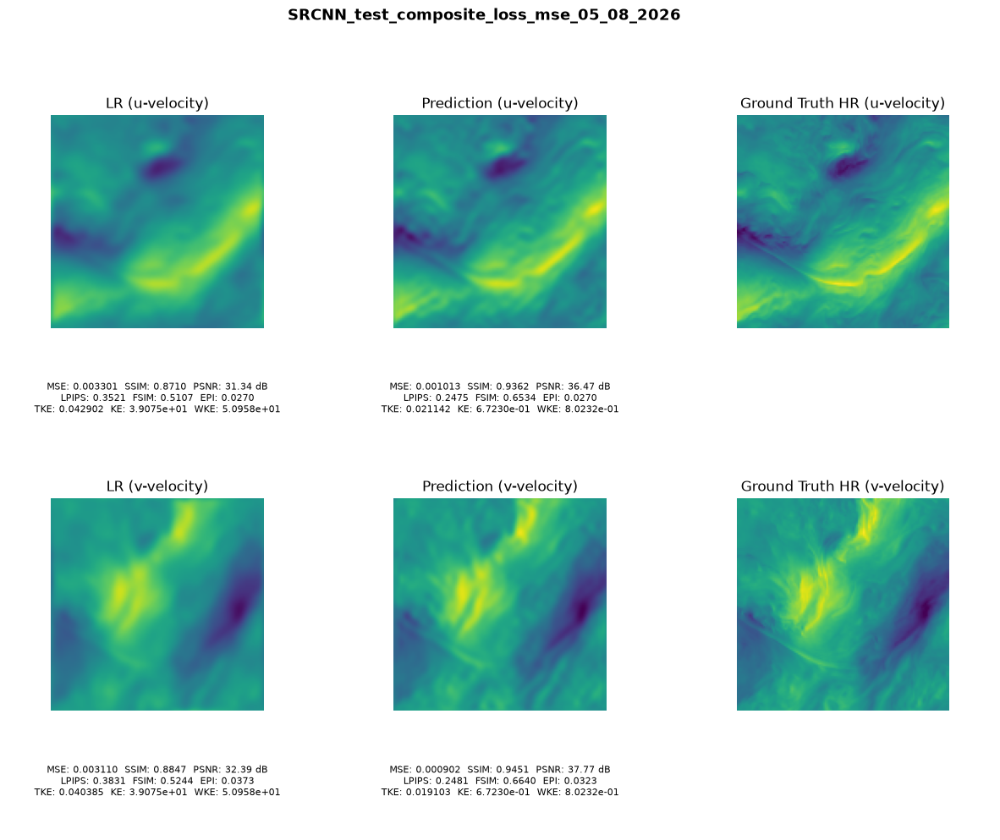


--- Evaluating SRCNN_test_composite_loss_mse_lpips_0.6_0.4_05_08_2026 (mse_lpips) ---
Weights: /home/lcadame/Vinicius_Thesis/Vinicius/models/SRCNN/test_composite_loss_mse_lpips_0.6_0.4_05_08_2026/output/weights/SRCNN_best.pth


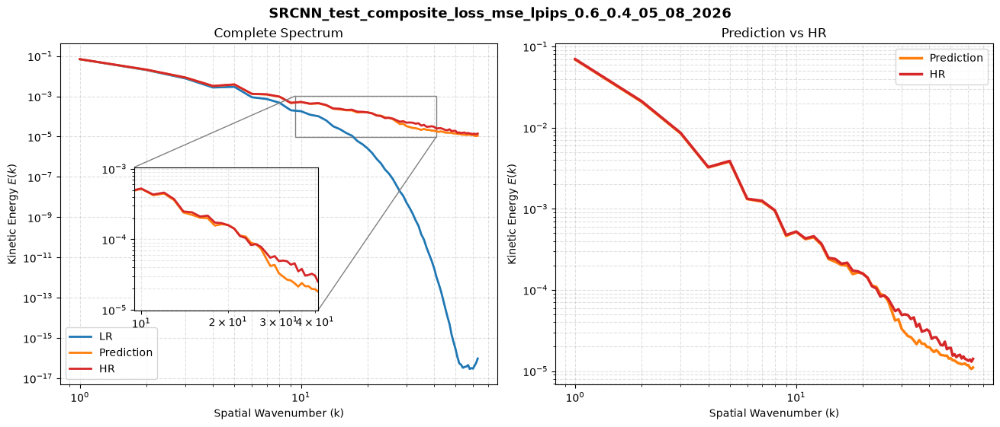

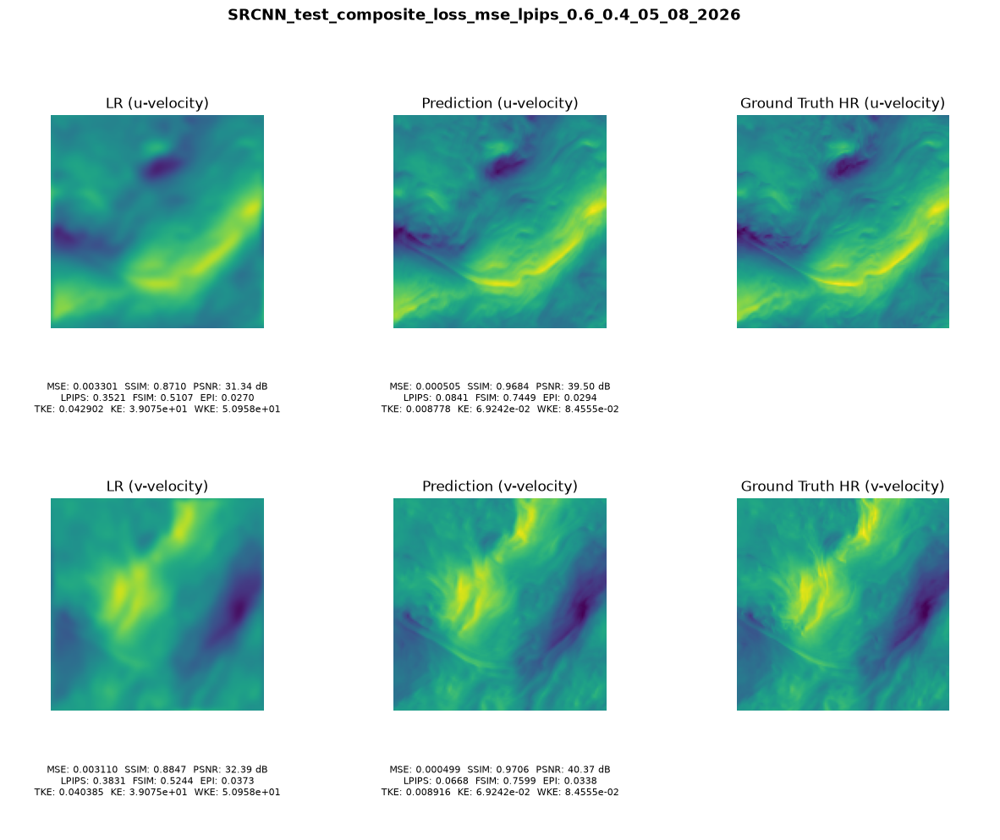


--- Evaluating SRCNN_test_composite_loss_mse_lpips_ke_0.6_0.2_0.2_05_08_2026 (mse_lpips_ke) ---
Weights: /home/lcadame/Vinicius_Thesis/Vinicius/models/SRCNN/test_composite_loss_mse_lpips_ke_0.6_0.2_0.2_05_08_2026/output/weights/SRCNN_best.pth


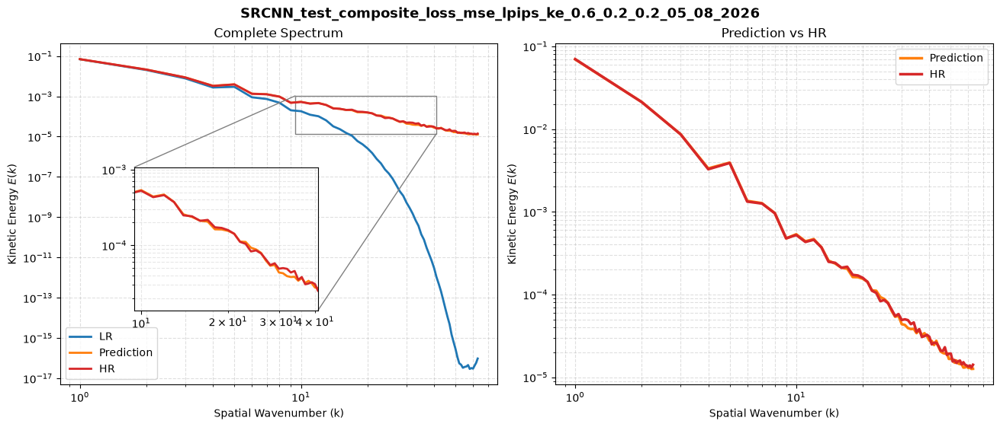

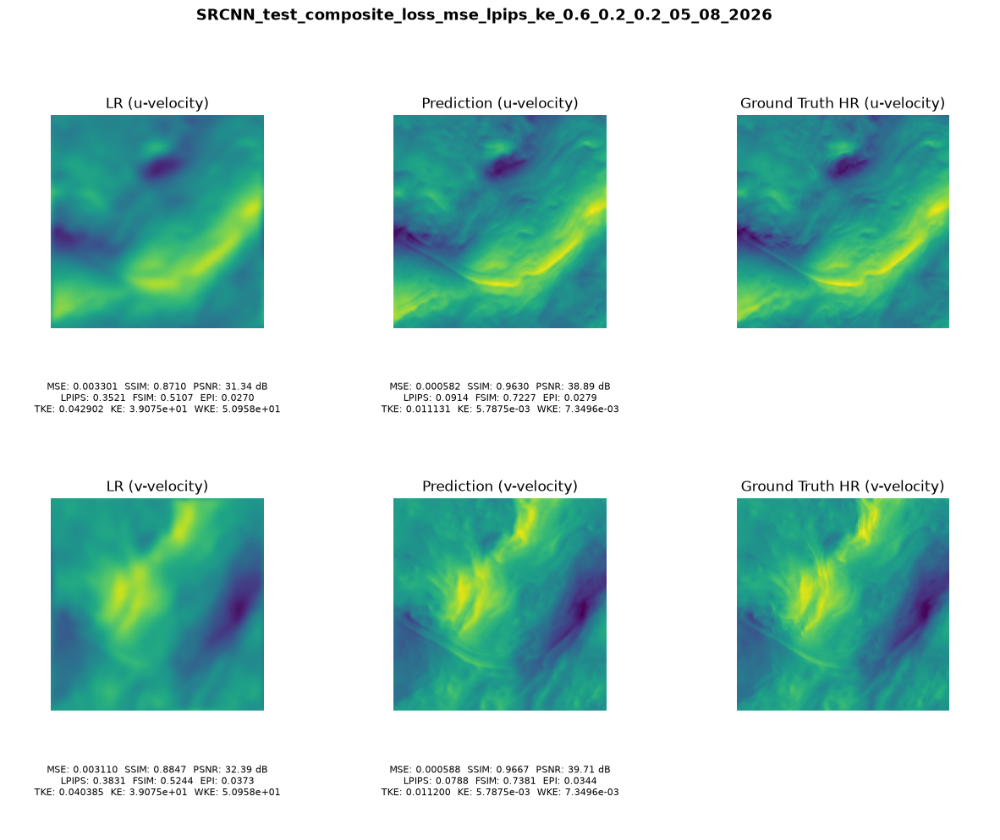


--- Evaluating SRCNN_test_composite_loss_mse_wke_0.6_0.4 (mse_lpips_ke) ---
Weights: /home/lcadame/Vinicius_Thesis/Vinicius/models/SRCNN/test_composite_loss_mse_wke_0.6_0.4/19_08_2026_120007/output/weights/SRCNN_best.pth


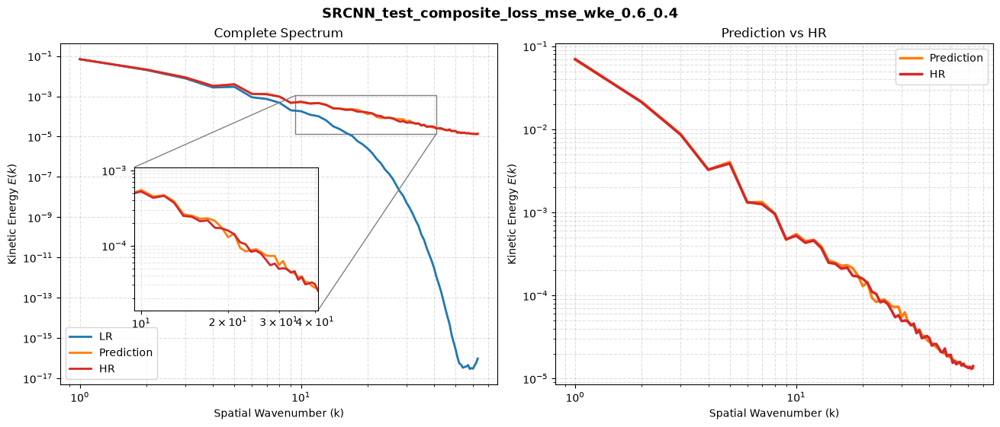

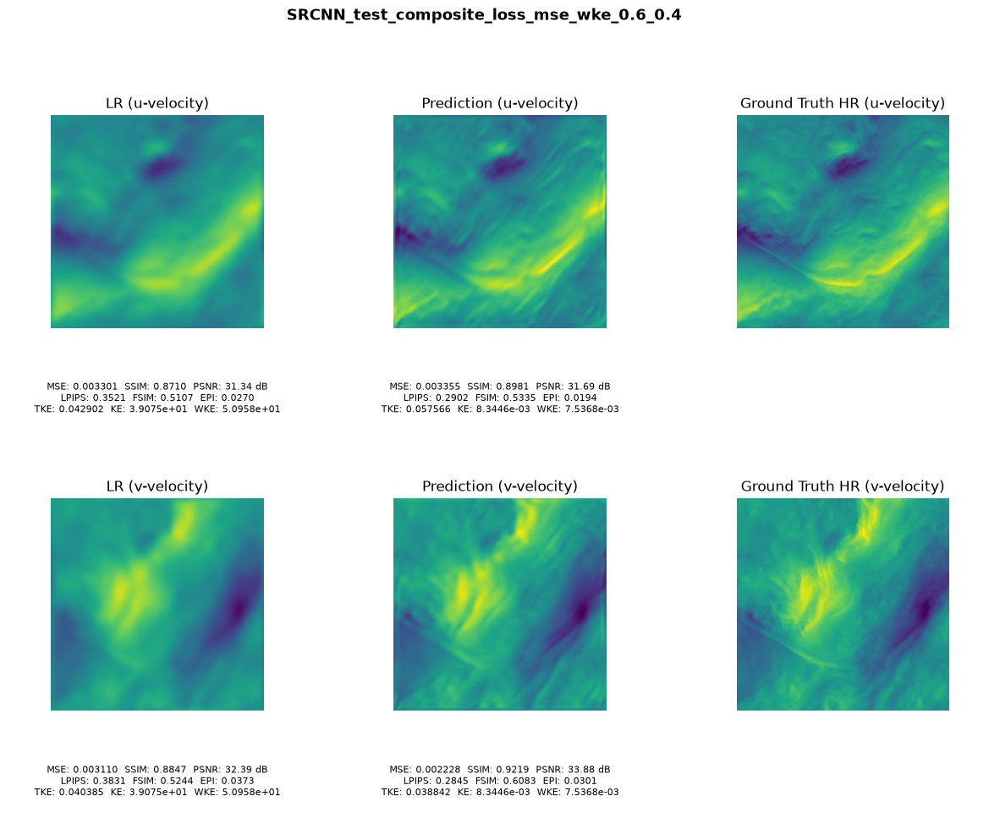


--- Evaluating DSCMS_test_composite_loss_mse_05_08_2026 (mse) ---
Weights: /home/lcadame/Vinicius_Thesis/Vinicius/models/DSCMS/test_composite_loss_mse_05_08_2026/output/weights/DSCMS_best.pth


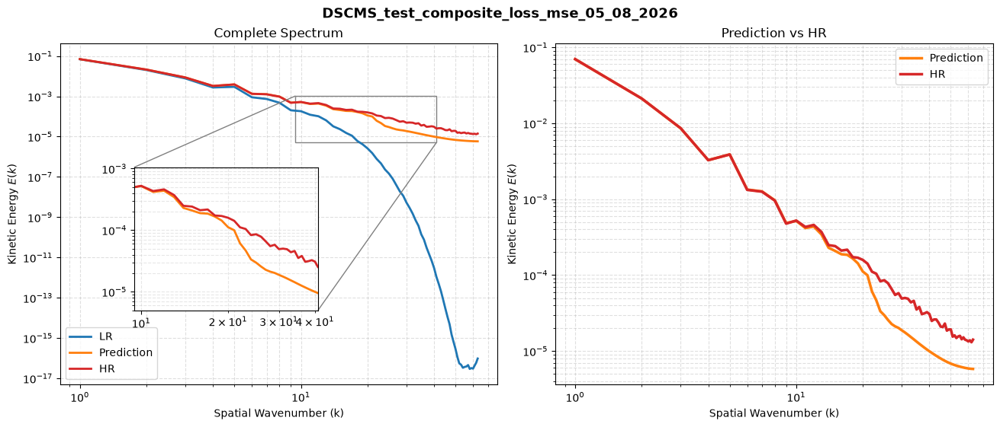

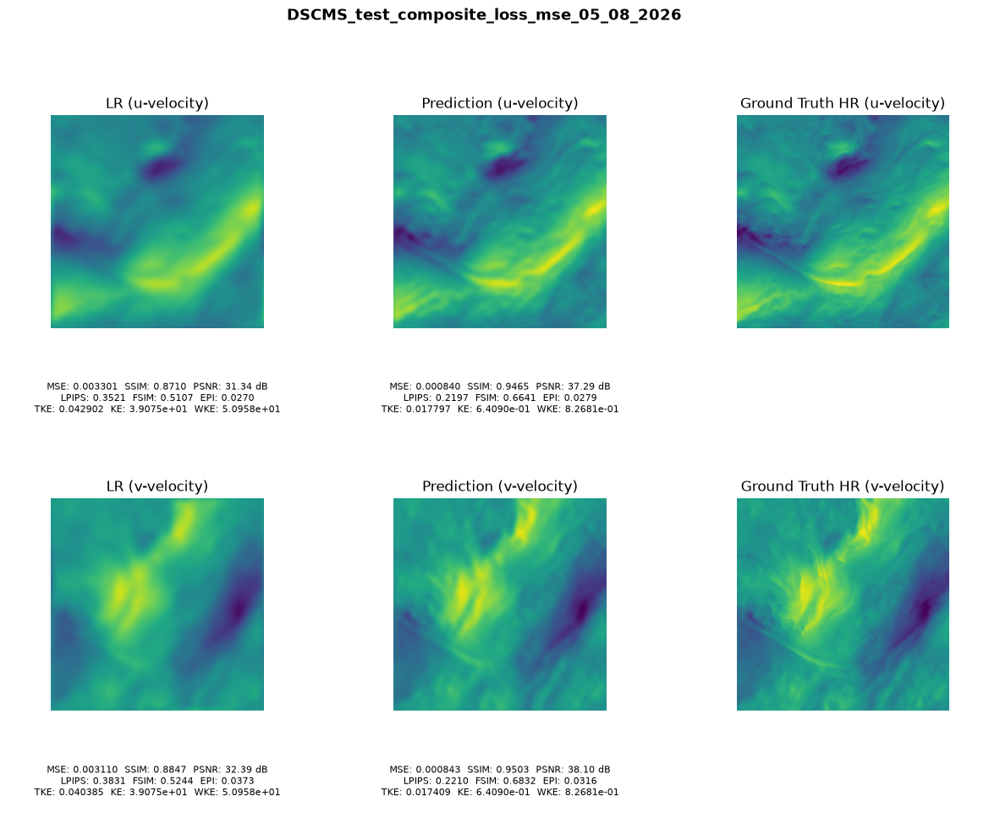


--- Evaluating DSCMS_test_composite_loss_mse_lpips_0.6_0.4_05_08_2026 (mse_lpips) ---
Weights: /home/lcadame/Vinicius_Thesis/Vinicius/models/DSCMS/test_composite_loss_mse_lpips_0.6_0.4_05_08_2026/output/weights/DSCMS_best.pth


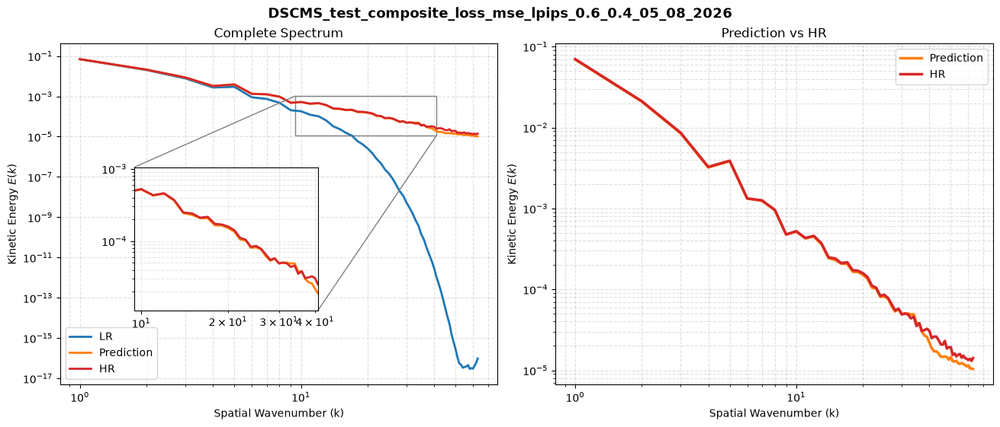

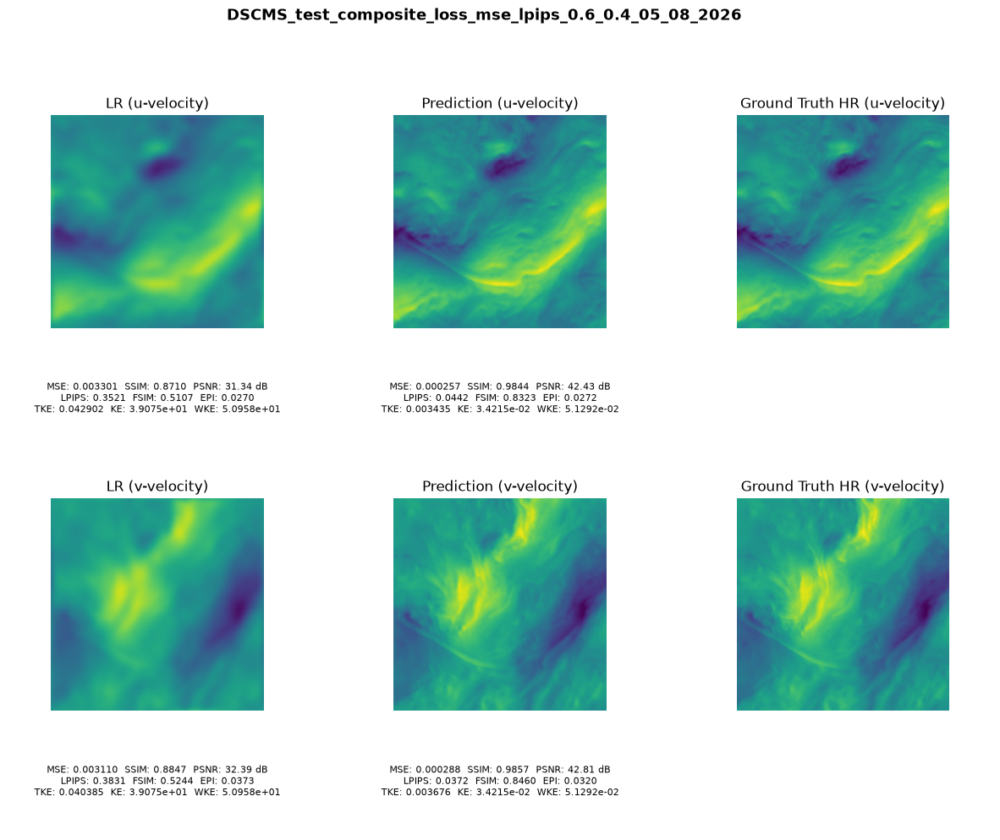


--- Evaluating DSCMS_test_composite_loss_mse_lpips_ke_0.6_0.2_0.2_05_08_2026 (mse_lpips_ke) ---
Weights: /home/lcadame/Vinicius_Thesis/Vinicius/models/DSCMS/test_composite_loss_mse_lpips_ke_0.6_0.2_0.2_05_08_2026/output/weights/DSCMS_best.pth


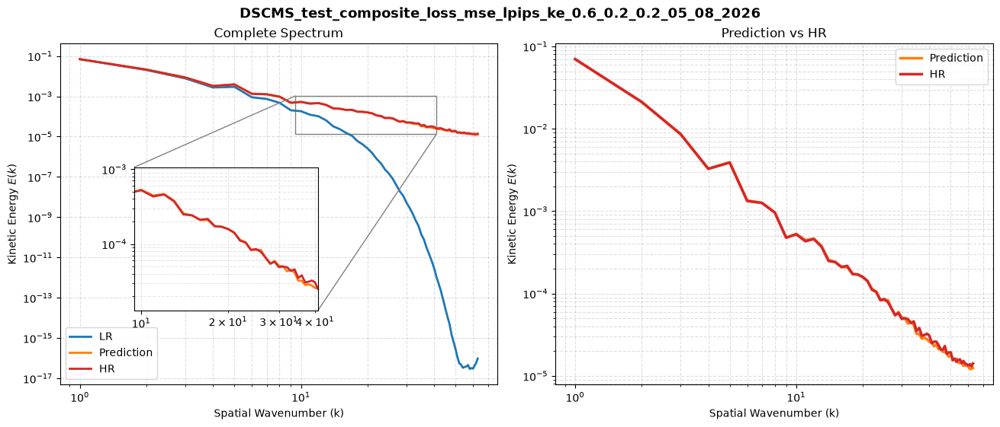

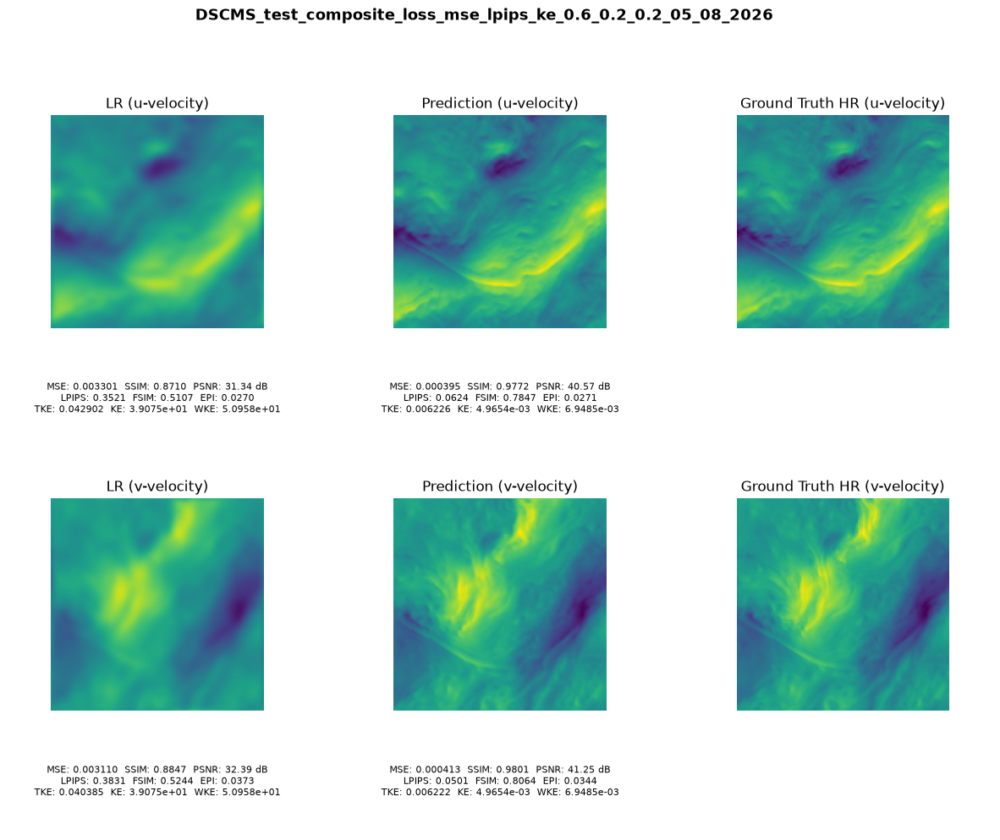


--- Evaluating DSCMS_test_composite_loss_mse_wke_0.6_0.4 (mse_lpips_ke) ---
Weights: /home/lcadame/Vinicius_Thesis/Vinicius/models/DSCMS/test_composite_loss_mse_wke_0.6_0.4/19_08_2026_121537/output/weights/DSCMS_best.pth


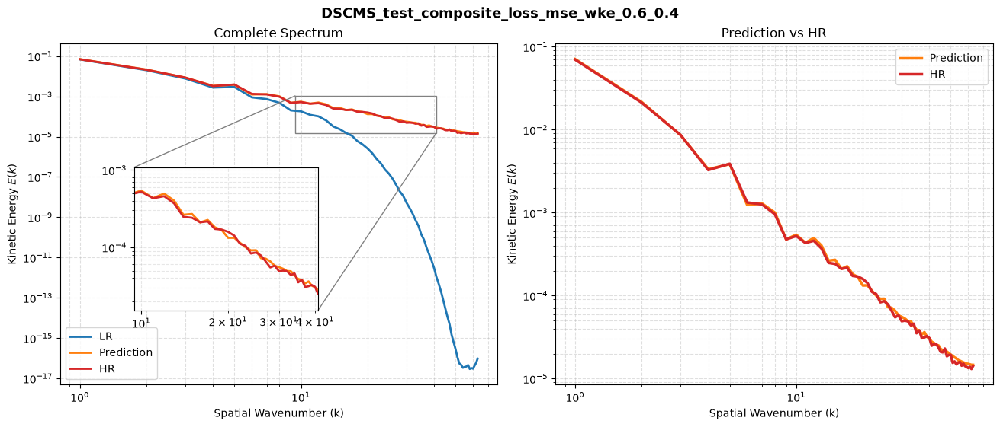

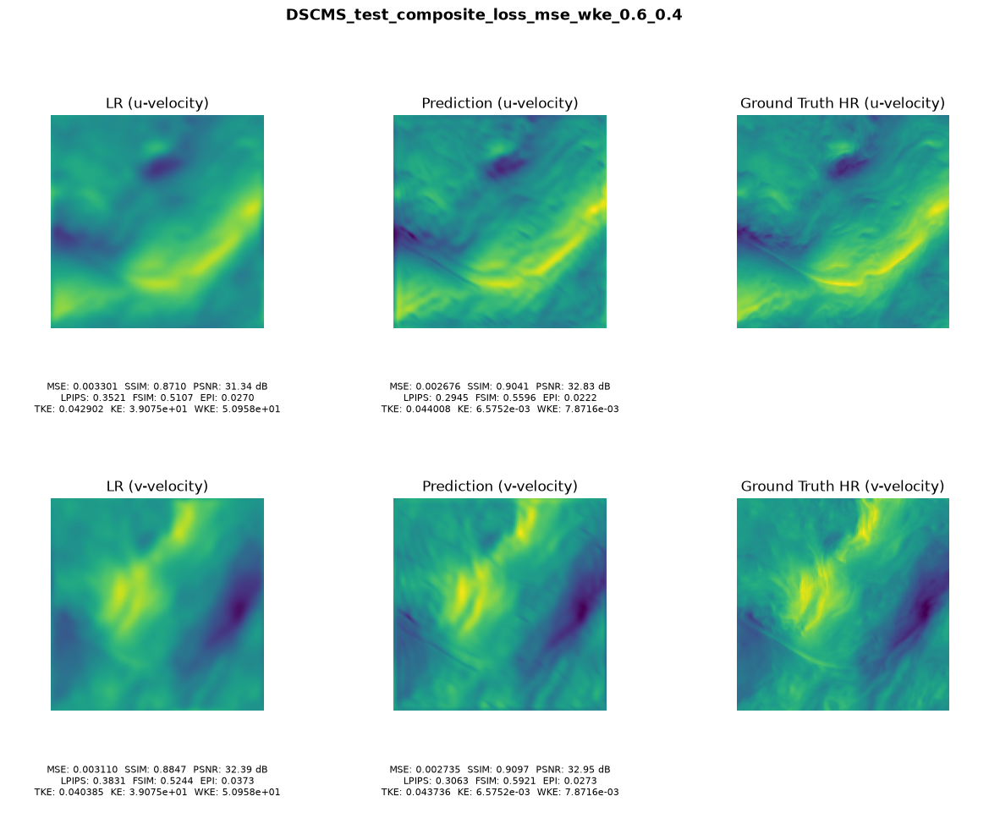


--- Evaluating PRUSR_test_composite_loss_mse_05_08_2026 (mse) ---
Weights: /home/lcadame/Vinicius_Thesis/Vinicius/models/PRUSR/test_composite_loss_mse_05_08_2026/output/weights/PRUSR_best.pth


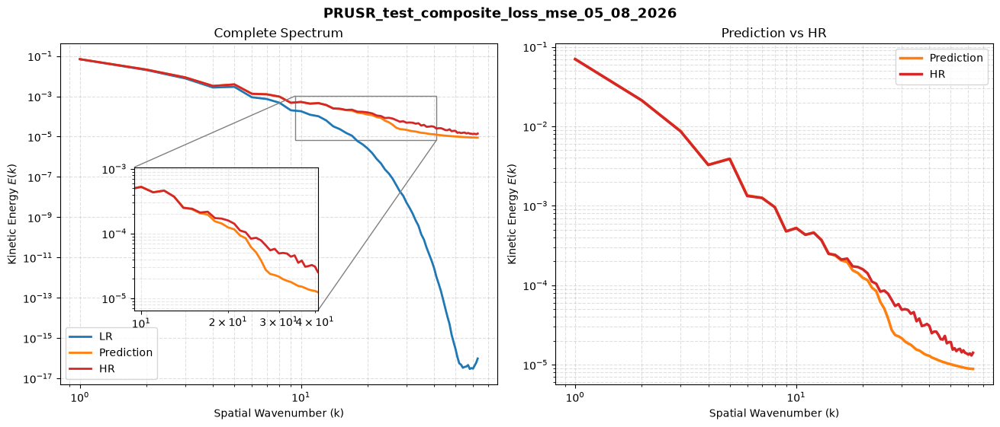

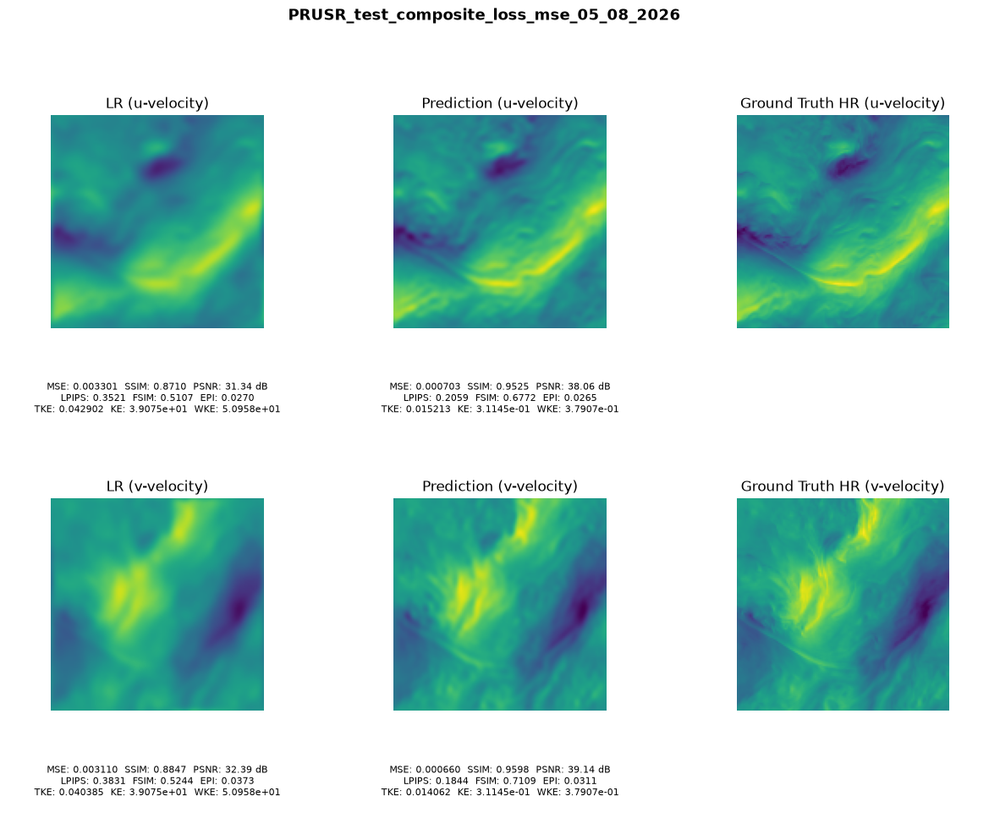


--- Evaluating PRUSR_test_composite_loss_mse_10_08_2026 (mse) ---
Weights: /home/lcadame/Vinicius_Thesis/Vinicius/models/PRUSR/test_composite_loss_mse_10_08_2026/output/weights/PRUSR_best.pth


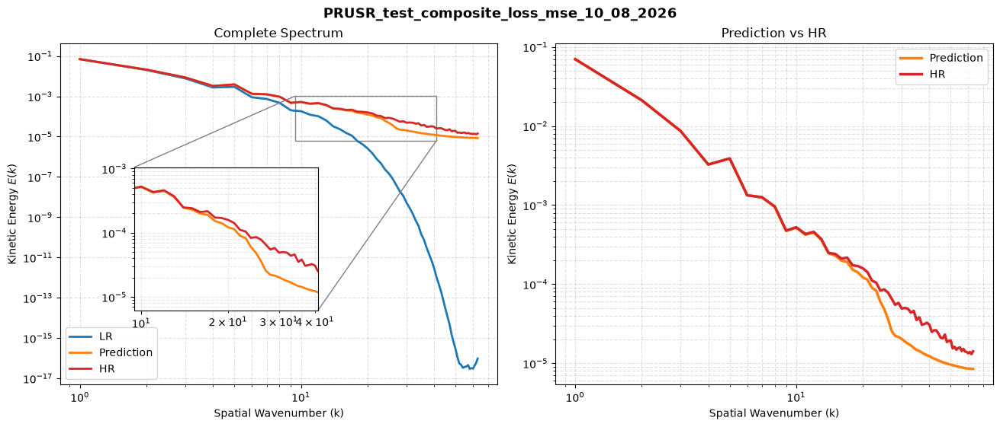

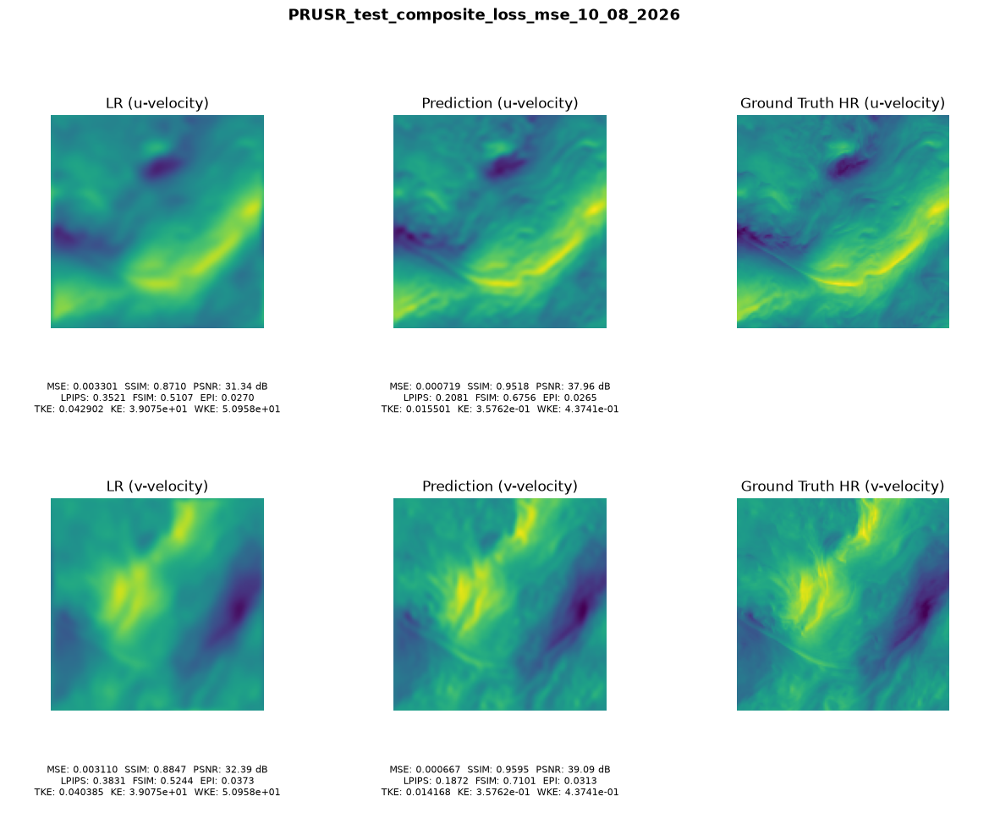


--- Evaluating PRUSR_test_composite_loss_mse_lpips_0.6_0.4_05_08_2026 (mse_lpips) ---
Weights: /home/lcadame/Vinicius_Thesis/Vinicius/models/PRUSR/test_composite_loss_mse_lpips_0.6_0.4_05_08_2026/output/weights/PRUSR_best.pth


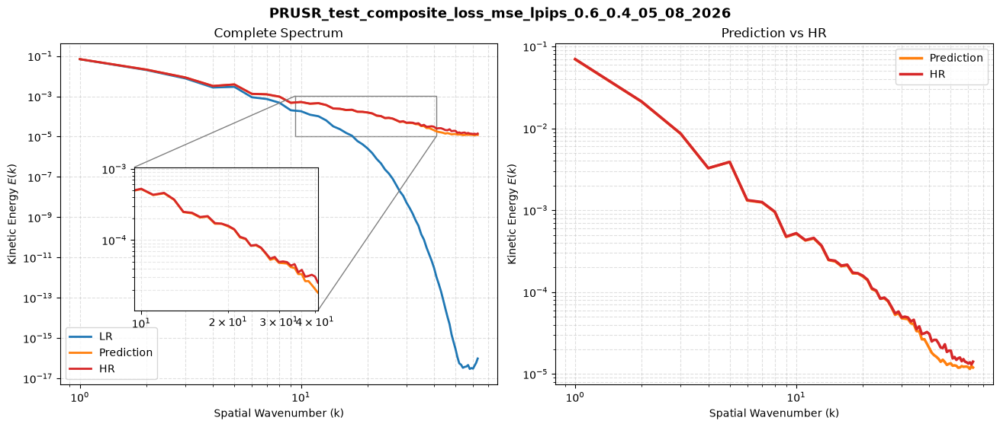

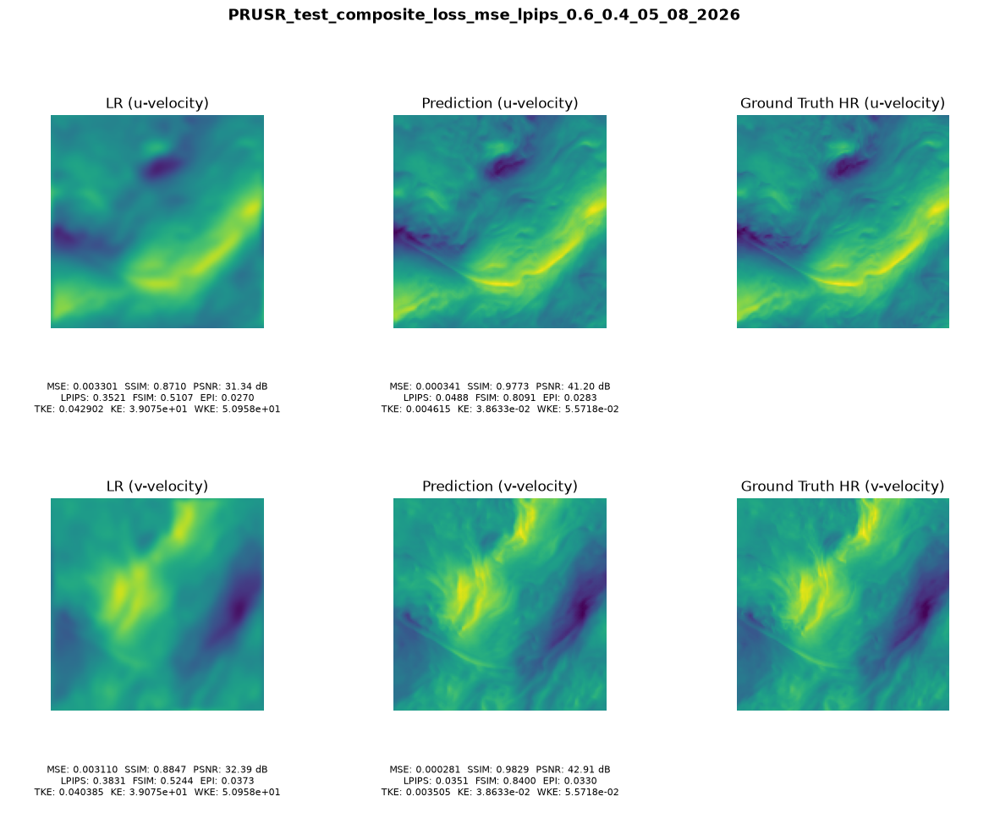


--- Evaluating PRUSR_test_composite_loss_mse_lpips_ke_0.6_0.2_0.2_05_08_2026 (mse_lpips_ke) ---
Weights: /home/lcadame/Vinicius_Thesis/Vinicius/models/PRUSR/test_composite_loss_mse_lpips_ke_0.6_0.2_0.2_05_08_2026/output/weights/PRUSR_best.pth


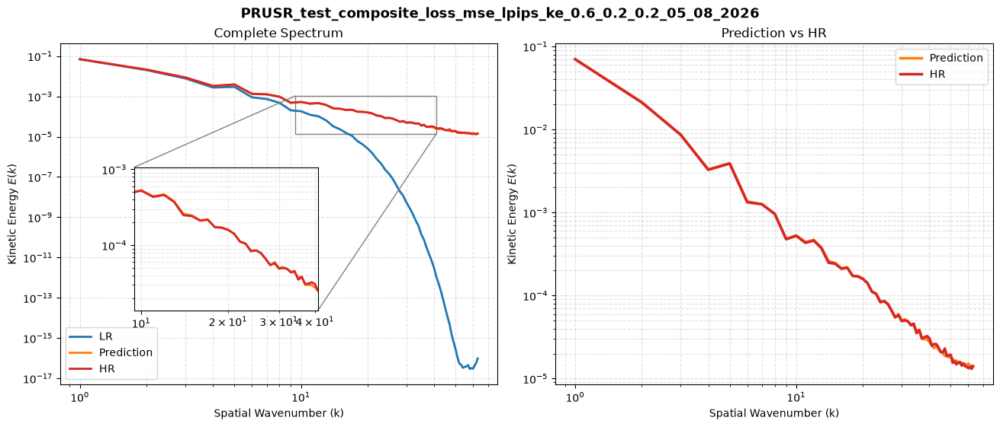

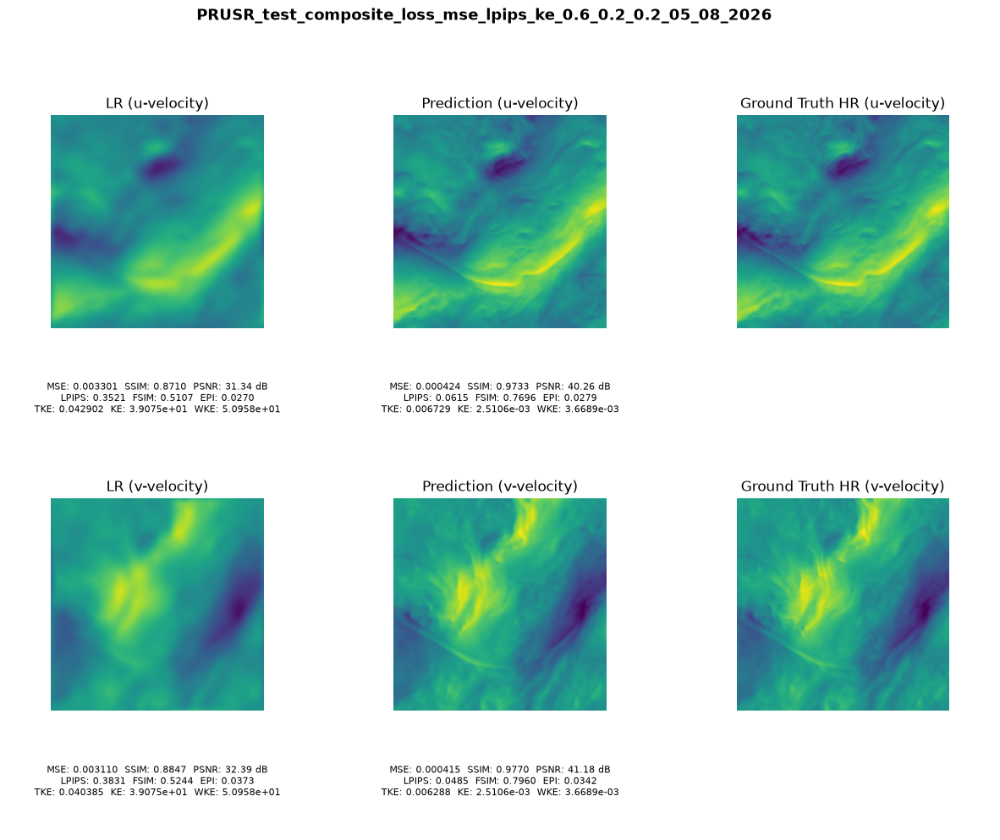


--- Evaluating PRUSR_test_composite_loss_mse_wke_0.6_0.4 (mse_lpips_ke) ---
Weights: /home/lcadame/Vinicius_Thesis/Vinicius/models/PRUSR/test_composite_loss_mse_wke_0.6_0.4/19_08_2026_133629/output/weights/PRUSR_best.pth


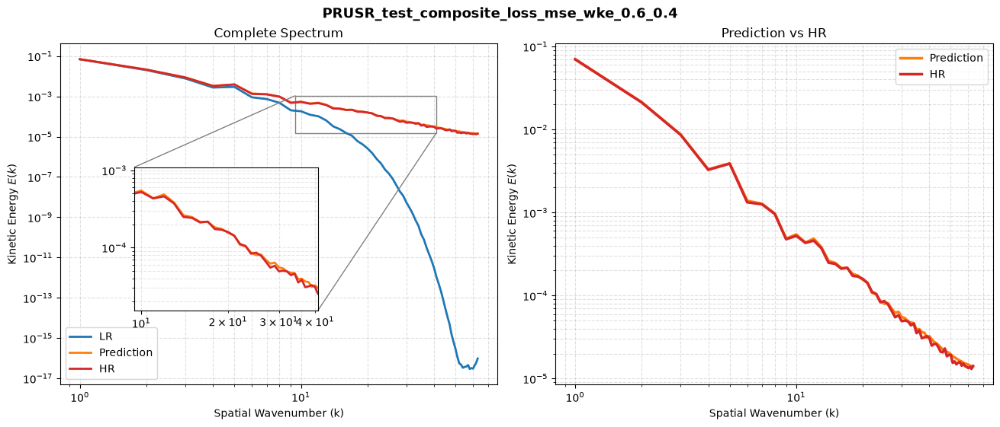

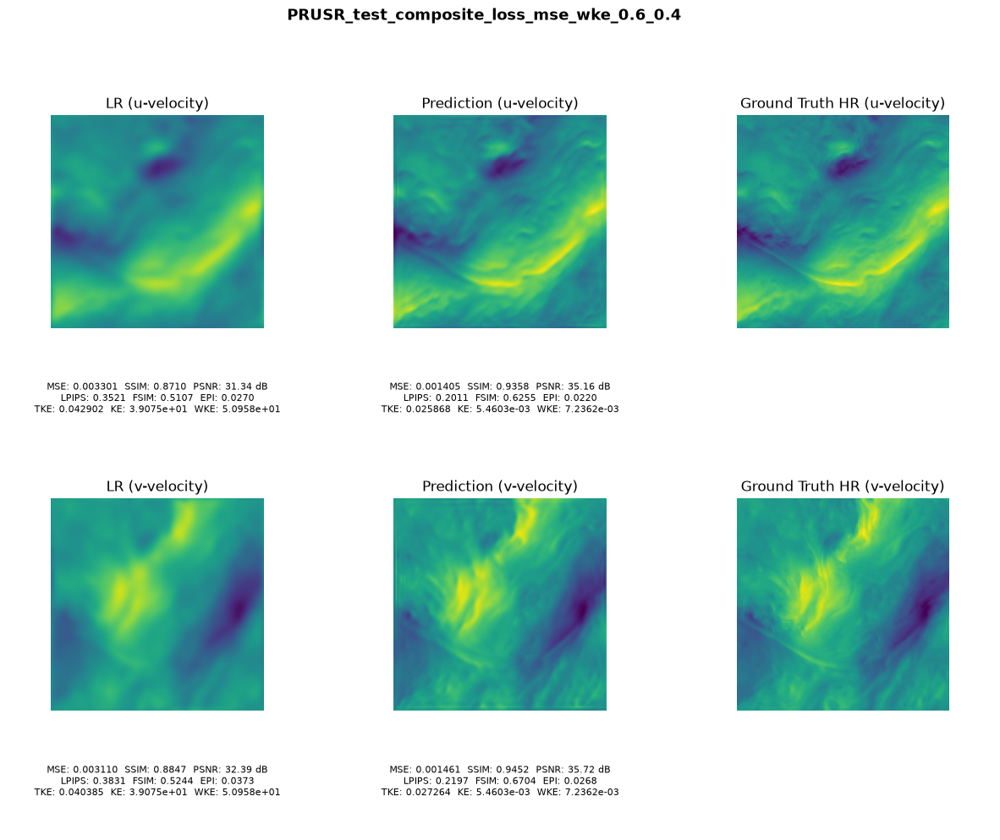


--- Evaluating SoFoNO_test_composite_loss_mse (mse) ---
Weights: /home/lcadame/Vinicius_Thesis/Vinicius/models/SoFoNO/test_composite_loss_mse/18_08_2026_125238/output/weights/SOFONO_best.pth


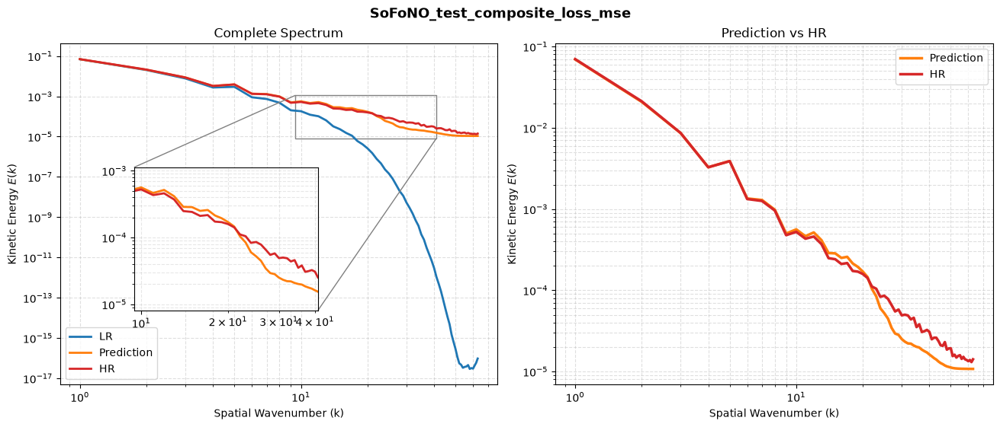

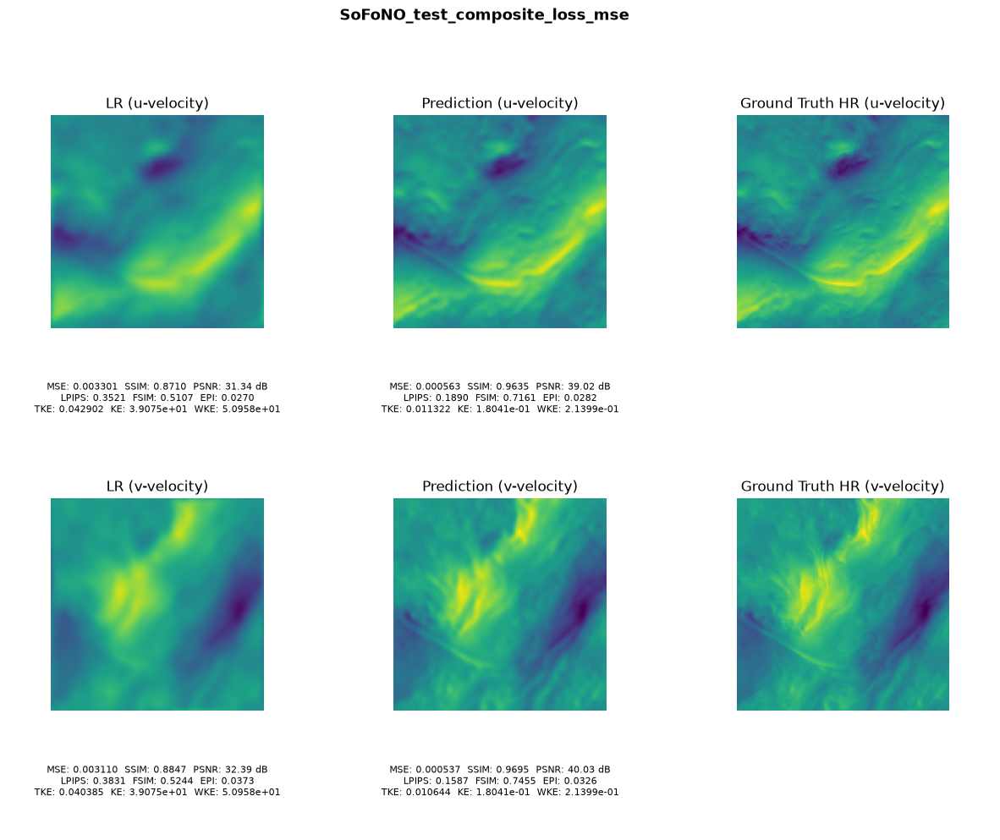


--- Evaluating SoFoNO_test_composite_loss_mse_lpips_0.6_0.4 (mse_lpips) ---
Weights: /home/lcadame/Vinicius_Thesis/Vinicius/models/SoFoNO/test_composite_loss_mse_lpips_0.6_0.4/18_08_2026_145054/output/weights/SOFONO_best.pth


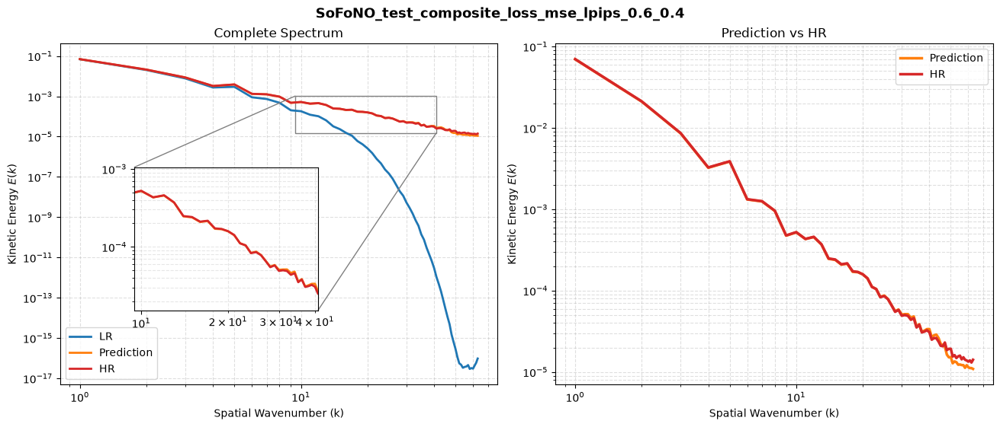

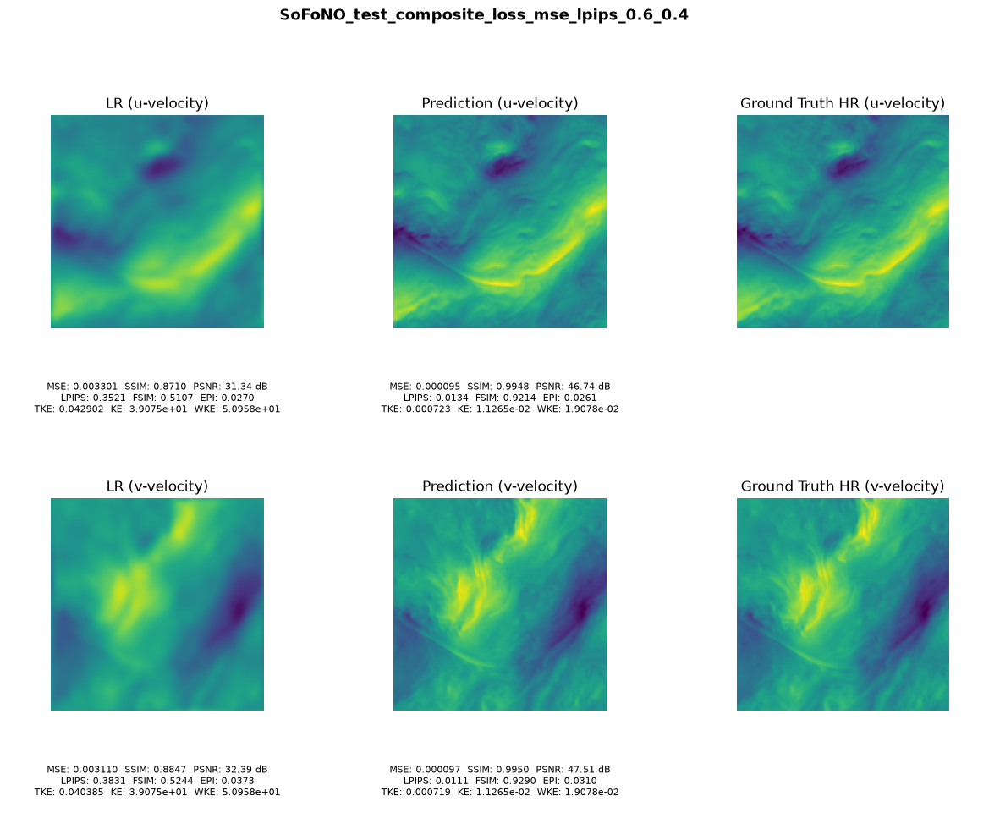


--- Evaluating SoFoNO_test_composite_loss_mse_lpips_ke_0.6_0.2_0.2 (mse_lpips_ke) ---
Weights: /home/lcadame/Vinicius_Thesis/Vinicius/models/SoFoNO/test_composite_loss_mse_lpips_ke_0.6_0.2_0.2/18_08_2026_213017/output/weights/SOFONO_best.pth


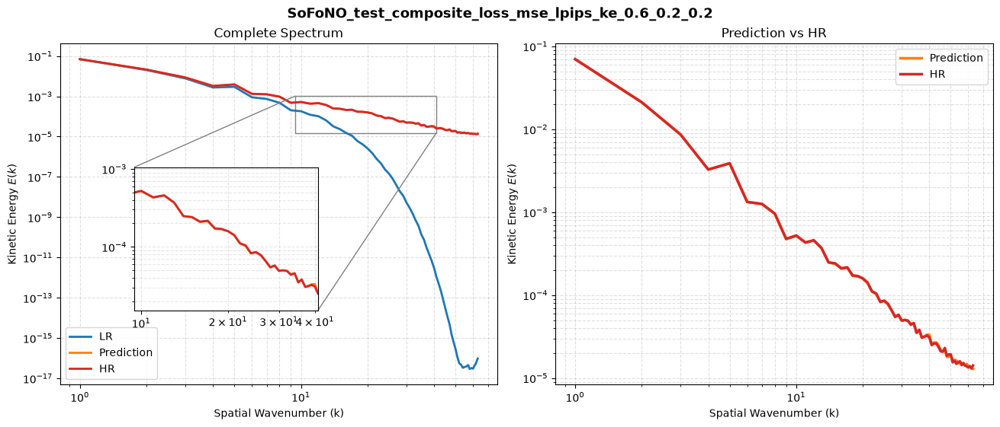

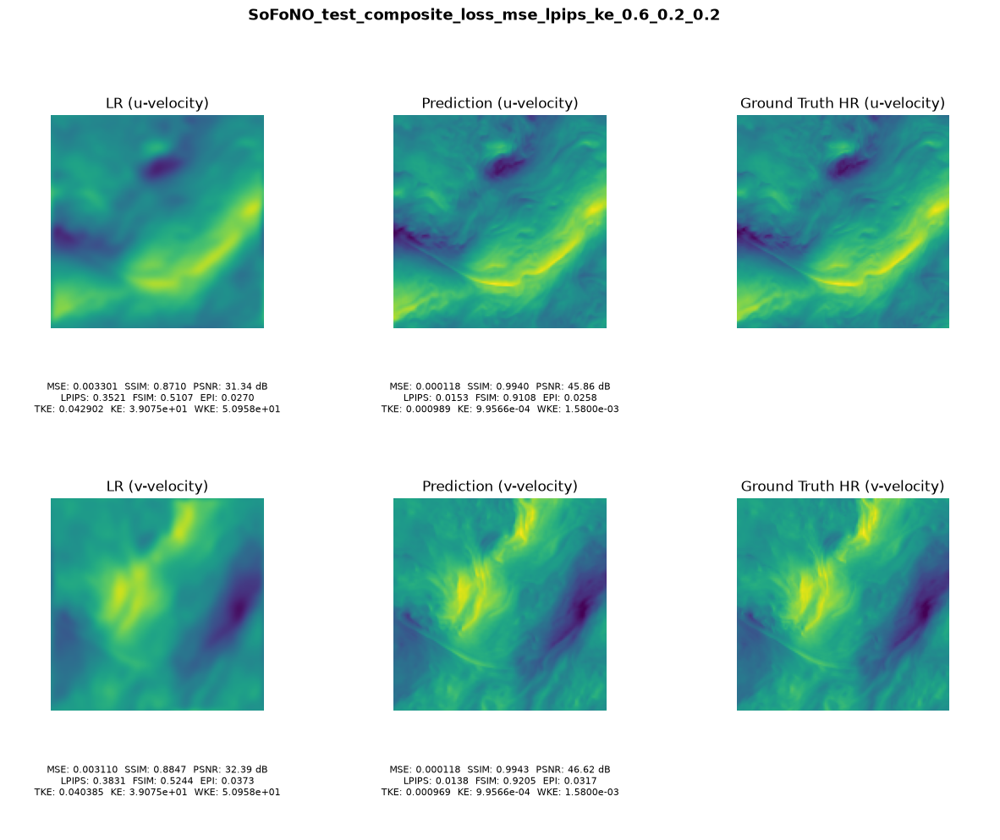


--- Evaluating SoFoNO_test_composite_loss_mse_wke_0.6_0.4 (mse_lpips_ke) ---
Weights: /home/lcadame/Vinicius_Thesis/Vinicius/models/SoFoNO/test_composite_loss_mse_wke_0.6_0.4/20_08_2026_010343/output/weights/SOFONO_best.pth


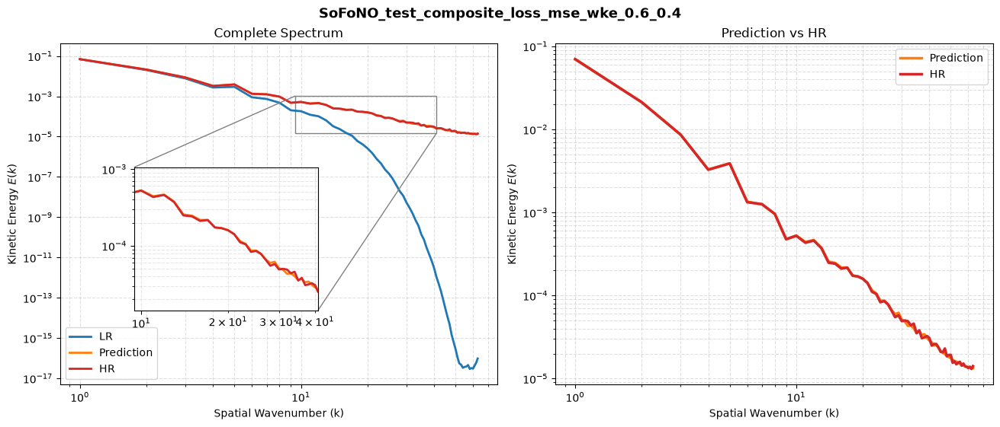

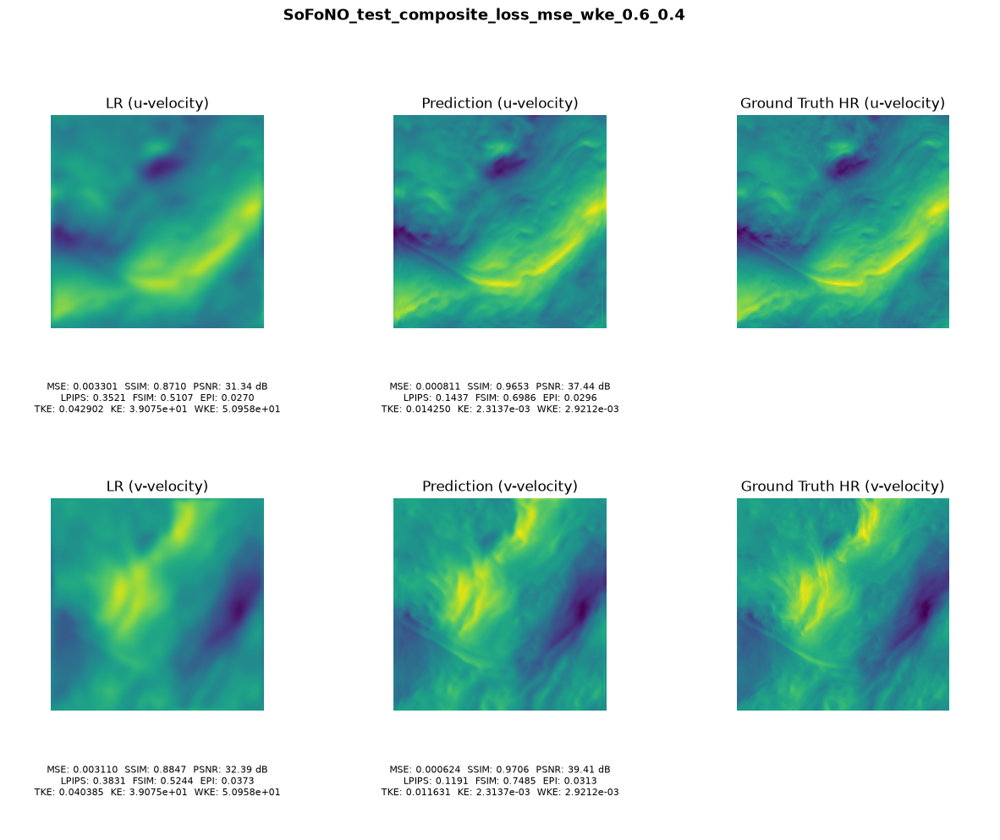


--- Evaluating SRNO_test_composite_loss_mse (mse) ---
Weights: /home/lcadame/Vinicius_Thesis/Vinicius/models/SRNO/test_composite_loss_mse/17_08_2026_214640/output/weights/SRNO_best.pth


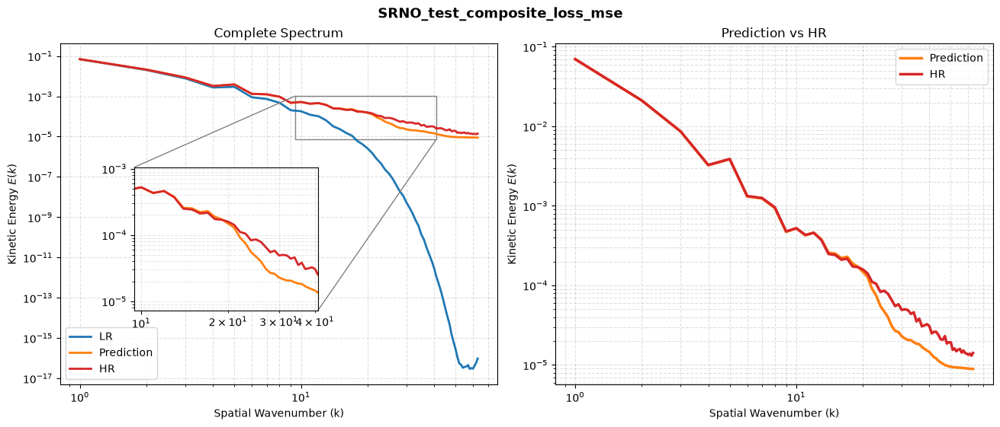

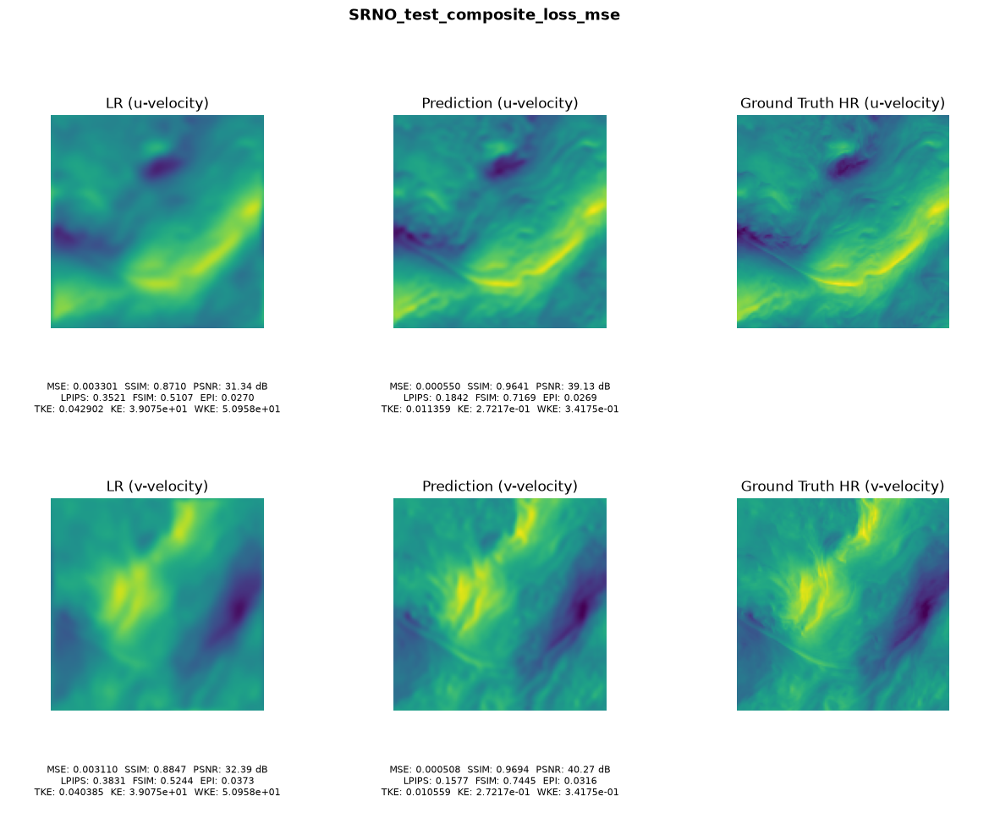


--- Evaluating SRNO_test_composite_loss_mse_lpips_0.6_0.4 (mse_lpips) ---
Weights: /home/lcadame/Vinicius_Thesis/Vinicius/models/SRNO/test_composite_loss_mse_lpips_0.6_0.4/17_08_2026_231300/output/weights/SRNO_best.pth


In [ ]:
all_results = {}

for model_name in MODELS_TO_TEST:
    checkpoints = find_checkpoints(model_name)
    if not checkpoints:
        print(f"Skipping {model_name}: no checkpoints found under {BASE_MODEL_DIR}/{model_name}/")
        continue

    for experiment_name, weight_path in checkpoints:
        strategy = categorize_strategy(experiment_name)
        run_label = f"{model_name}_{experiment_name}"
        print(f"\n--- Evaluating {run_label} ({strategy}) ---")
        print(f"Weights: {weight_path}")

        model = load_model(model_name, weight_path)

        # 1. Average metrics over the full test set
        metrics = evaluate_model(model, test_loader, device)
        metrics["strategy"] = strategy
        all_results[run_label] = metrics

        # 2. Qualitative plots for a fixed sample (same SAMPLE_IDX every run)
        lr, hr = test_dataset[SAMPLE_IDX]
        lr, hr = lr.unsqueeze(0).to(device), hr.unsqueeze(0).to(device)
        with torch.no_grad():
            pred = model(lr)

        plot_ke_spectrum(
            run_label,
            lr.squeeze(0).cpu().numpy(),
            pred.squeeze(0).detach().cpu().numpy(),
            hr.squeeze(0).cpu().numpy(),
            save_path=os.path.join(PLOTS_DIR, f"{run_label}_ke_spectrum.png"),
        )

        plot_sample_comparison(
            run_label, lr, pred, hr,
            save_path=os.path.join(PLOTS_DIR, f"{run_label}_sample_comparison.png"),
        )


## Aggregate results table

In [ ]:
rows = []
for experiment, metrics in all_results.items():
    row = {"Experiment": experiment, "Strategy": metrics.pop("strategy")}
    for metric_name, value in metrics.items():
        if set(value.keys()) == {"u", "v"}:
            row[f"{metric_name}_u_mean"] = value["u"]["mean"]
            row[f"{metric_name}_v_mean"] = value["v"]["mean"]
        else:
            row[f"{metric_name}_mean"] = value["mean"]
    rows.append(row)

df_results = pd.DataFrame(rows)
df_results.to_csv(RESULTS_CSV, index=False)

print(f"\nSaved {len(df_results)} rows to {RESULTS_CSV}")
df_results
